# ⚽ **AICE ASSOCIATE 제5회 실전모의고사**
## **축구 유망주 예측**
---
* **도메인**: 스포츠 매니지먼트
* **목 표**: 축구 선수의 신체 및 기술 데이터를 활용하여 미래의 **유망주 여부를 예측**하는 인공지능 모델 개발
* 대한민국 최고의 유망주 발굴 에이전시 **'골든 스카우터'** 는 지금까지 베테랑 스카우터의 주관적인 경험에 의존해왔으나, 시간과 비용의 한계로 인해 잠재력 있는 선수를 놓치는 문제가 지속적으로 발생하고 있다.
* 이러한 문제를 해결하기 위해, 에이전시의 데이터 분석팀은 선수의 나이, 신체 조건, 기술 능력치 등 다양한 데이터를 종합적으로 분석하여 과학적인 스카우팅 시스템을 도입하려 한다.
* 축적된 선수 데이터를 기반으로 어린 선수가 미래의 월드클래스로 성장할 가능성이 높은 **유망주(Prospect)인지 여부를 예측**하는 최적의 분류 모델을 개발한다.
---

## 모범 답안

답안 셀에 실습 데이터로 실행한 결과를 저장했습니다. 다시 실행하려면 위에서부터 순서대로 실행하세요.

8-2의 컬럼 개수에는 문항에서 지정한 encoding_df의 타깃 컬럼도 포함됩니다. 13번은 14번의 load_model()에서 읽을 수 있도록 검증 정확도가 가장 높은 시점의 전체 모델을 .keras 파일로 저장합니다.

In [1]:
from pathlib import Path

import tensorflow as tf

# 원본 파일 위치를 작업 폴더 또는 그 상위 폴더에서 찾습니다.
cwd = Path.cwd()
exam_root = next(
    (folder / '[실습 파일] FINAL TEST 실전모의고사' for folder in (cwd, *cwd.parents)
     if (folder / '[실습 파일] FINAL TEST 실전모의고사').is_dir()),
    None,
)
if exam_root is None:
    raise FileNotFoundError('AICE Associate 폴더에서 Jupyter를 실행하세요.')

data_dir = exam_root / '제5회 실전모의고사'
checkpoint_dir = exam_root.parent / '실전 모의고사 답안' / '학습결과' / '제5회'


**[데이터셋 소개]**
football_prospects.csv

**[데이터 컬럼 설명]**
* ID: 선수의 고유 식별자
* Age: 나이
* Height: 키 (cm)
* Weight: 몸무게 (kg)
* Position: 주 포지션
* Preferred_Foot: 주로 쓰는 발
* Pace: 속력
* Stamina: 체력
* Strength: 몸싸움
* Shooting: 슈팅 능력
* Finishing: 골 결정력
* Dribbling: 드리블 능력
* BallControl: 공 컨트롤
* Passing: 패스 능력
* Vision: 시야
* Crossing: 크로스 정확도
* StandingTackle: 태클 능력
* Interceptions: 가로채기
* Reactions: 반응 속도
* Aggression: 적극성
* Jersey_Number: 등번호
* Sponsor_Code: 스폰서 코드
* Weekly_Wage: 주급
* Agent_Code: 에이전트 코드
* **Prospect: 유망주 여부(1: 유망주, 0: 일반) -> Target**
---

#### **1. 분석에 필요한 축구 선수 데이터셋을 로드하고 데이터의 기초 통계 정보를 확인하세요. 아래 가이드에 따라 데이터를 불러오고 특정 컬럼의 평균값을 확인하세요.**
---
* **(1-1) 데이터를 로드하고 요약 통계량을 출력하세요.**
    * 대상 파일: **`football_prospects.csv`**
    * **`pandas`** 라이브러리를 별칭 **`pd`** 를 사용하여 임포트하세요.
    * 데이터를 불러와 **`df`** 에 저장하세요.
    * **`describe()`** 메소드를 사용하여 수치형 데이터의 요약 통계량을 확인하세요.
* **(1-2) 'Age' 컬럼의 평균(mean) 값은 얼마인가요? (반올림하여 소수점 둘째 자리까지 표시)**
---

In [2]:
import pandas as pd

df = pd.read_csv(data_dir / 'football_prospects.csv')
df.describe()

,Age,Height,Weight,Pace,Stamina,Strength,Dribbling,BallControl,Shooting,Finishing,Passing,Vision,Crossing,StandingTackle,Reactions,Interceptions,Aggression,Jersey_Number,Prospect
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,4608.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,18.649200,181.912800,79.284400,62.894200,61.225200,55.458800,85.234400,73.899800,74.738400,60.594600,69.512000,44.971788,48.203600,55.703200,94.935000,62.060200,64.524800,49.617400,0.348400
std,1.279401,9.960614,11.493665,8.115823,6.469657,5.782092,7.731094,8.665794,7.101525,5.691742,8.286422,4.702394,4.779698,2.388274,3.406097,12.970822,14.495482,28.344652,0.476511
min,16.000000,165.000000,60.000000,40.000000,40.000000,40.000000,57.000000,44.000000,50.000000,41.000000,41.000000,40.000000,40.000000,47.000000,82.000000,40.000000,40.000000,1.000000,0.000000
25%,18.000000,173.000000,69.000000,57.000000,57.000000,52.000000,80.000000,68.000000,70.000000,57.000000,64.000000,40.000000,45.000000,54.000000,93.000000,51.000000,52.000000,25.000000,0.000000
50%,19.000000,182.000000,79.000000,63.000000,61.000000,55.000000,85.000000,74.000000,75.000000,61.000000,70.000000,45.000000,48.000000,56.000000,95.000000,62.000000,64.000000,49.500000,0.000000
75%,20.000000,190.000000,89.000000,68.000000,66.000000,59.000000,91.000000,80.000000,79.250000,64.250000,75.000000,48.000000,51.000000,57.000000,98.000000,73.000000,77.000000,74.000000,1.000000
max,22.000000,199.000000,99.000000,99.000000,86.000000,76.000000,99.000000,99.000000,99.000000,80.000000,99.000000,65.000000,66.000000,64.000000,99.000000,84.000000,89.000000,98.000000,1.000000


In [3]:
print(f"{df['Age'].mean():.2f}")

18.65


> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**
>

In [4]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

#### **2. 타겟 변수의 분포를 확인하고 학습할 문제의 유형을 판별하세요. 아래 가이드에 따라 시각화를 수행하고 결과에 따른 분석 유형을 정의하세요.**
---
* **(2-1) 라이브러리를 활용하여 타깃 변수의 분포를 시각화하세요.**
    * **`seaborn`** 라이브러리를 사용하세요.
    * **`countplot()`** 함수를 사용하여 타깃 변수인 **`Prospect`** 의 분포를 막대그래프로 시각화하세요.
    * 그래프의 제목을 **'Prospect Distribution'** 으로 설정하세요.
* **(2-2) 타깃 변수 'Prospect'의 데이터 특성에 따른 문제 유형은 무엇인가요?**
---

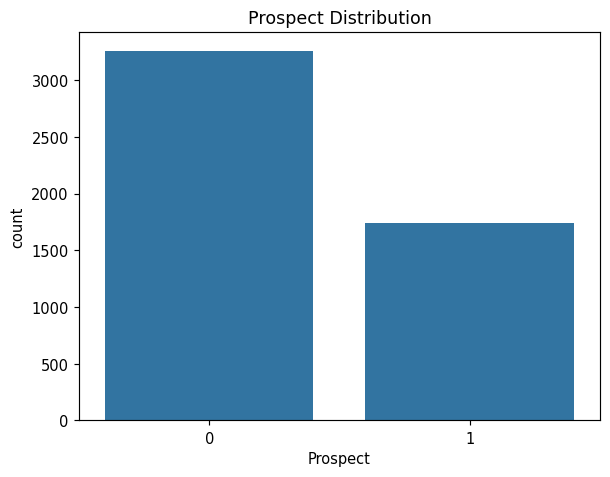

In [5]:
sns.countplot(data=df, x='Prospect')
plt.title('Prospect Distribution')
plt.show()

In [ ]:
# 답: 분류(이진 분류)

#### **3. 스카우팅 조건에 부합하는 특정 선수군을 필터링하고 최적의 유망주 정보를 확인하세요. 아래 가이드에 따라 특정 포지션과 주발 조건을 충족하는 선수들을 추출하고 정렬하여 골 결정력이 가장 우수한 선수를 선별하세요.**
---
* 대상 데이터: **`df`**
* **`Position`** 이 **'FW'** 이고 **`Preferred_Foot`** 이 **'Left'** 인 선수를 필터링하여 **`df_3`** 에 저장하세요.
* 필터링된 데이터를 **`Finishing`** (골 결정력) 능력치 기준으로 **내림차순** 정렬하세요.
* 정렬된 데이터에서 골 결정력이 가장 높은 **상위 1순위 선수 정보**를 출력하여 확인하세요.
---

In [6]:
df_3 = df.loc[df['Position'].eq('FW') & df['Preferred_Foot'].eq('Left')].sort_values(
    'Finishing', ascending=False
)
df_3.head(1)

,ID,Age,Height,Weight,Position,Preferred_Foot,Pace,Stamina,Strength,Dribbling,BallControl,Shooting,Finishing,Passing,Vision,Crossing,StandingTackle,Reactions,Interceptions,Aggression,Jersey_Number,Sponsor_Code,Weekly_Wage,Agent_Code,Prospect
2560,TRAIN_2560,20,168,98,FW,Left,63,61,57,99,99,96,78,94,61.0,63,49,95,64,64,6,SPON_160,"€4,770",AGT-060,1


#### **4. 수치형 피처 간의 상관관계를 시각화하고 유망주 선정에 영향을 미치는 주요 요인을 분석하세요. 아래 가이드에 따라 수치형 데이터 간의 상관계수를 산출하고 히트맵(Heatmap)을 통해 시각화하여 유망주 여부(Prospect)와 가장 밀접한 기술 요소를 파악하세요.**
---
* **(4-1) 라이브러리를 활용하여 피처 간 상관관계를 시각화하세요.**
    * 대상 데이터: **`df`**
    * 모든 피처 간의 상관계수를 산출하여 **`df_4`** 변수에 저장하세요. (**`numeric_only=True`** 옵션 적용)
    * **`matplotlib`** 을 사용하여 그래프의 크기를 가로 **12**, 세로 **10**으로 설정하세요.
    * **`seaborn`** 의 **`heatmap()`** 함수를 사용하여 상관관계를 시각화하세요.
    * 컬러맵은 **'coolwarm'**, 상관계수 값 표시(**`annot=True`**) 및 소수점 둘째 자리까지 표시(**`fmt=".2f"`**)하세요.
* **(4-2) 타깃 변수인 'Prospect'와 상관관계가 가장 높게 나타나는(절대값 기준) 기술 능력치 피처는 무엇인가요?**
---

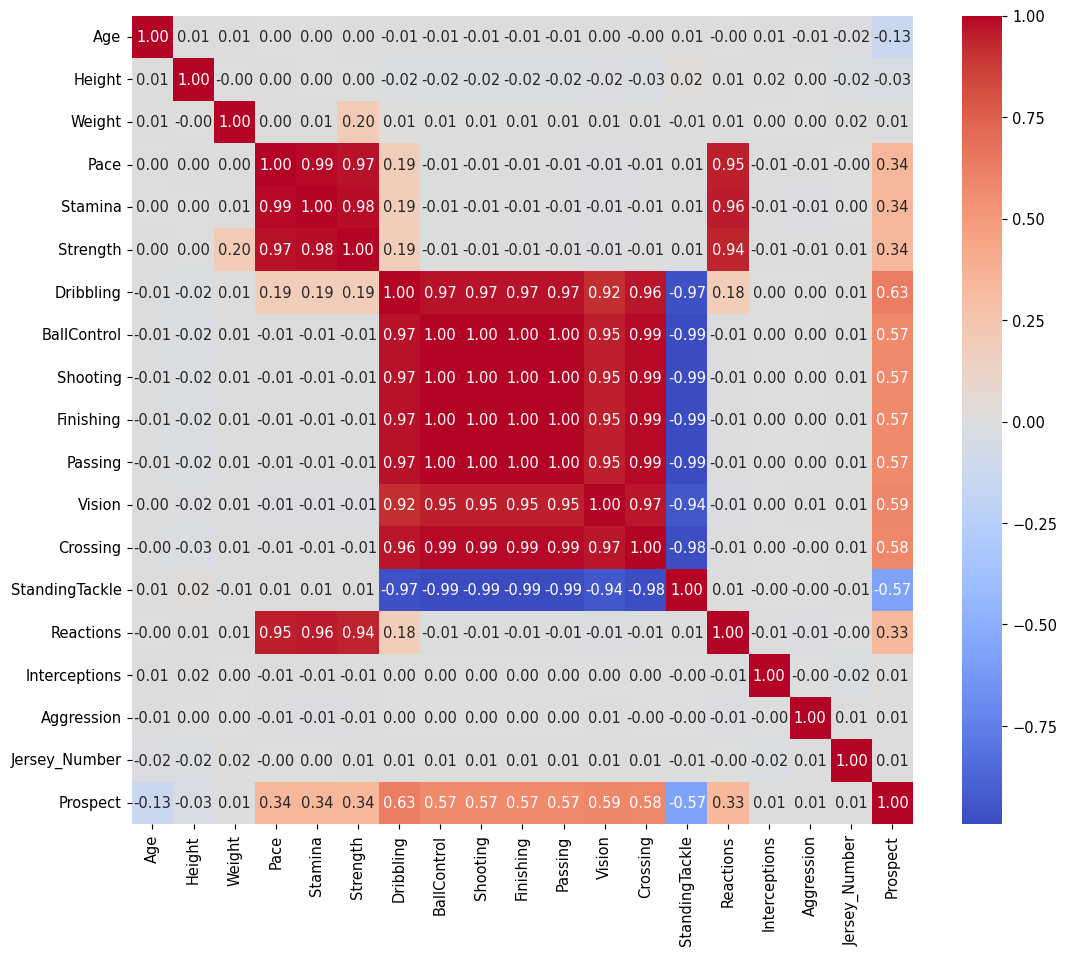

In [7]:
df_4 = df.corr(numeric_only=True)
plt.figure(figsize=(12, 10))
sns.heatmap(df_4, cmap='coolwarm', annot=True, fmt='.2f')
plt.show()

In [8]:
skills = df.loc[:, 'Pace':'Aggression'].columns
print(df_4.loc[skills, 'Prospect'].abs().idxmax())

Dribbling


#### **5. 선수의 신체 데이터를 활용하여 체질량지수(BMI) 파생 변수를 생성하고 그룹 간 차이를 분석하세요. 아래 가이드에 따라 'BMI' 피처를 생성하고, 유망주와 일반 선수 그룹 간의 신체적 특성 차이를 비교하세요.**
---
* **(5-1) 선수의 키와 몸무게를 이용하여 'BMI' 컬럼을 생성하는 코드를 작성하세요.**
    * 대상 데이터: **`df`**
    * BMI 산출 공식은 **`Weight (kg) / (Height (m))^2`** 입니다.
    * 단, **`Height`** 컬럼은 cm 단위이므로 m 단위로 변환하여 계산하세요.(Height/100)
    * 결과값을 **`df`** 의 새로운 컬럼인 **`BMI`** 에 저장하세요.
* **(5-2) 유망주(Prospect == 1) 그룹과 일반 선수(Prospect == 0) 그룹 중 평균 BMI가 더 높은 그룹은 어디인가요?**
---

In [9]:
df['BMI'] = df['Weight'] / (df['Height'] / 100) ** 2

In [10]:
mean_bmi = df.groupby('Prospect')['BMI'].mean().rename(index={0: '일반', 1: '유망주'})
print(mean_bmi)
print(mean_bmi.idxmax())

Prospect
일반     24.098506
유망주    24.321215
Name: BMI, dtype: float64
유망주


#### **6. 불필요한 컬럼을 제거하고 특정 피처의 데이터 타입을 수치형으로 변환하여 데이터를 정제하세요. 아래 가이드에 따라 학습에 사용하지 않는 식별자 정보를 삭제하고, 문자열 형태의 임금 데이터를 분석 가능한 수치형으로 정제하세요.**
---
* 대상 데이터: **`df`**
* 불필요한 컬럼 리스트(**`['ID', 'Jersey_Number', 'Sponsor_Code', 'Agent_Code', 'BMI']`**)를 삭제하고 결과값을 **`drop_df`** 에 저장하세요.
* **`drop_df`** 의 **`Weekly_Wage`** 컬럼에서 유로화 기호(**'€'**)와 쉼표(**','**)를 제거하고 **`float`** 타입으로 변환하세요.
---

In [11]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요.
cols_to_drop = ['ID', 'Jersey_Number', 'Sponsor_Code', 'Agent_Code', 'BMI']
drop_df = df.drop(columns=cols_to_drop)

drop_df['Weekly_Wage'] = drop_df['Weekly_Wage'].str.replace('€', '').str.replace(',', '').astype(float)

drop_df['Weekly_Wage'].head()

0    2235.0
1    3992.0
2    2710.0
3    5229.0
4    4417.0
Name: Weekly_Wage, dtype: float64

In [ ]:
# 답: drop

In [ ]:
# 답: replace

In [ ]:
# 답: astype

#### **7. 'Vision'(시야) 컬럼의 결측치를 중앙값으로 보간하여 데이터의 정합성을 확보하세요. 아래 가이드에 따라 결측치가 존재하는 피처를 찾아 중앙값(Median)으로 채우고, 제공된 코드의 오류를 찾아 올바르게 수정하세요.**
---
* **(7-1) 다음은 'Vision' 컬럼의 결측치를 중앙값으로 채우려는 코드이나, 실행 후 원본 데이터에 결과가 반영되지 않는 오류가 발생했습니다. 오류의 원인을 파악하여 코드를 수정하세요.**
    * 대상 데이터: **`drop_df`**
* **(7-2) 결측치 처리가 완료된 후, `drop_df` 의 'Vision' 컬럼에 남아있는 결측치의 개수는 몇 개인가요?**
---

In [12]:
drop_df['Vision'] = drop_df['Vision'].fillna(drop_df['Vision'].median())
print(drop_df.isna().sum())

Age               0
Height            0
Weight            0
Position          0
Preferred_Foot    0
Pace              0
Stamina           0
Strength          0
Dribbling         0
BallControl       0
Shooting          0
Finishing         0
Passing           0
Vision            0
Crossing          0
StandingTackle    0
Reactions         0
Interceptions     0
Aggression        0
Weekly_Wage       0
Prospect          0
dtype: int64


In [13]:
print(drop_df['Vision'].isna().sum())

0


#### **8. 범주형 데이터를 수치형으로 변환하여 모델 학습을 위한 데이터셋을 완성하세요. 아래 가이드에 따라 모델이 학습 가능한 형태로 변환하세요.**
---
* **(8-1) 라이브러리를 활용하여 두 개의 범주형 컬럼을 원-핫 인코딩하는 코드를 작성하세요.**
    * 대상 데이터: **`drop_df`**
    * **`pandas`** 라이브러리를 사용해서 **`Position`** 과 **`Preferred_Foot`** 컬럼을 원-핫 인코딩하세요.
    * 변환된 결과를 **`encoding_df`** 변수에 저장하세요.
    * 다중공선성(Dummy Variable Trap)' 문제를 방지하세요.
    * 변환된 데이터프레임의 정보를 출력하여(**`info()`**) 구조를 확인하세요.
* **(8-2) 인코딩이 완료된 후, `encoding_df` 의 전체 컬럼(Feature) 개수는 총 몇 개인가요?**
---

In [14]:
encoding_df = pd.get_dummies(drop_df, columns=['Position', 'Preferred_Foot'], drop_first=True)
encoding_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   5000 non-null   int64  
 1   Height                5000 non-null   int64  
 2   Weight                5000 non-null   int64  
 3   Pace                  5000 non-null   int64  
 4   Stamina               5000 non-null   int64  
 5   Strength              5000 non-null   int64  
 6   Dribbling             5000 non-null   int64  
 7   BallControl           5000 non-null   int64  
 8   Shooting              5000 non-null   int64  
 9   Finishing             5000 non-null   int64  
 10  Passing               5000 non-null   int64  
 11  Vision                5000 non-null   float64
 12  Crossing              5000 non-null   int64  
 13  StandingTackle        5000 non-null   int64  
 14  Reactions             5000 non-null   int64  
 15  Interceptions        

In [15]:
print(encoding_df.shape[1])

23


#### **9. 데이터를 학습용과 테스트용으로 분리하고 피처의 스케일을 표준화하세요. 아래 가이드에 따라 데이터를 분리하고 스케일링을 수행하여 모델 학습을 위한 최종 준비를 마치세요.**
---
* 대상 데이터: **`encoding_df`**
* **`Prospect`** 컬럼을 타깃으로 하여 독립 변수(**`X`**)와 종속 변수(**`y`**)를 분리하세요.
* **`sklearn`** 라이브러리를 사용하여 학습용과 테스트용 데이터를 **8:2** 비율로 분리하세요.
    * 재현성을 위해 난수 시드 **42**로 설정하세요.
    * 타깃 변수의 클래스 비율을 유지하기 위해 **`stratify`** 옵션을 적용하세요.
    * 분리된 데이터를 **`X_train, X_test, y_train, y_test`** 에 저장하세요.
* **`StandardScaler`** 를 사용하여 데이터의 스케일을 표준화하되, 아래 기준을 적용하세요.
    * 스케일러가 **학습 데이터**의 통계량(평균, 표준편차)만을 추출하도록 설정하세요.
    * 추출된 기준을 **학습 및 검증 데이터**에 각각 적용하여 수치 변환을 완료하세요.
---

In [16]:
# (코드 셀) 지시사항에 따라 코드의 빈칸을 채우고 실행하세요.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = encoding_df.drop('Prospect', axis=1)
y = encoding_df['Prospect']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"학습 데이터 형태: {X_train.shape}")
print(f"테스트 데이터 형태: {X_test.shape}")

학습 데이터 형태: (4000, 22)
테스트 데이터 형태: (1000, 22)


In [ ]:
# 답: 0.2

In [ ]:
# 답: y

In [ ]:
# 답: X_train

In [ ]:
# 답: X_test

#### **10. 다양한 머신러닝 알고리즘을 학습시키고 최적의 유망주 예측 모델을 선정하세요. 아래 가이드에 따라 여러 분류 모델을 학습시키고, 검증 데이터에 대한 정확도(Accuracy)를 비교하여 가장 성능이 우수한 모델을 선정하세요.**
---
* **(10-1) 세 가지 알고리즘(Logistic Regression, Decision Tree, Random Forest)을 학습하고 정확도를 출력하는 코드를 작성하세요.**
    * 대상 데이터: **`X_train_scaled`**, **`X_test_scaled`**, **`y_train`**, **`y_test`**
    * **`sklearn`** 라이브러리에서 **`LogisticRegression`**, **`DecisionTreeClassifier`**, **`RandomForestClassifier`** 를 각각 임포트하여 사용하세요.
    * 각 모델 생성 시 재현성을 위해 **`random_state=42`** 를 지정하세요. (LogisticRegression은 제외 가능)
    * 학습 데이터로 모델을 학습시킨 후, 검증 데이터에 대한 정확도(**`accuracy_score`**)를 각각 산출하여 출력하세요.
* **(10-2) 세 모델 중 예측 성능이 가장 높게 나타난 모델은 무엇인가요? (클래스 이름으로 작성)**
---

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

lr_model = LogisticRegression(random_state=42)
dt_model = DecisionTreeClassifier(random_state=42)
rf_model = RandomForestClassifier(random_state=42)
scores = {}
for model in (lr_model, dt_model, rf_model):
    model.fit(X_train_scaled, y_train)
    name = type(model).__name__
    scores[name] = accuracy_score(y_test, model.predict(X_test_scaled))
    print(f'{name}: {scores[name]:.5f}')

LogisticRegression: 0.86300
DecisionTreeClassifier: 0.80100
RandomForestClassifier: 0.85500


In [18]:
print(max(scores, key=scores.get))

LogisticRegression


#### **11. 학습된 모델의 피처 중요도(Feature Importance)를 시각화하는 과정에서 코드 오류가 발생했다. 아래 가이드를 참고해서  코드 오류를 정정하고, 유망주 결정의 핵심 요인을 분석하세요.**
---
* **(11-1) 피처 중요도 시각화**
    - 대상 모델: **`rf_model`** (문제 10에서 학습시킨 모델)
    - 피처 이름(**`X.columns`**)과 피처별 중요도를 매칭하여 데이터프레임을 생성한 후, 중요도 기준 **내림차순**으로 정렬하세요.
    - 상위 **10건**의 데이터만 **`fi_df`** 변수에 저장하세요.
    - **`seaborn`** 의 **`barplot()`** 을 사용하여 시각화하세요. (그래프 크기: 가로 6, 세로 5)
* **(11-2) 시각화 결과, 가장 중요도가 높게 나타난 1순위 피처는 무엇인가요?**
---

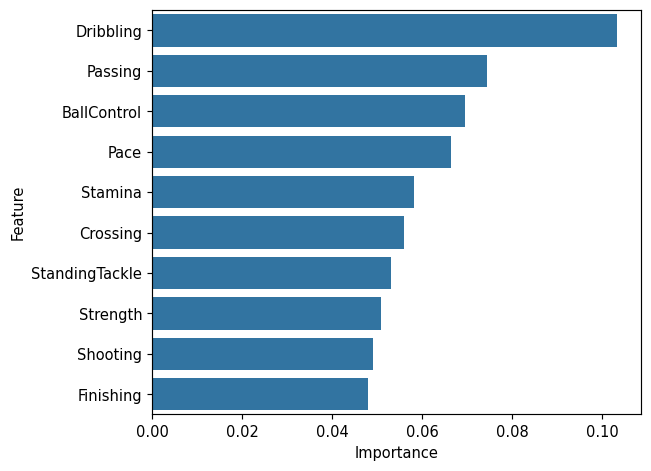

In [19]:
fi_df = pd.DataFrame({'Feature': X.columns, 'Importance': rf_model.feature_importances_})
fi_df = fi_df.sort_values(by='Importance', ascending=False).head(10)
plt.figure(figsize=(6, 5))
sns.barplot(x='Importance', y='Feature', data=fi_df)
plt.show()

In [20]:
print(fi_df['Feature'].iloc[0])

Dribbling


> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**
>

In [21]:
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical
tf.keras.utils.set_random_seed(100)

#### **12. 아래 지시사항에 따라 유망주(Prospect)를 예측하기 위한 딥러닝 모델을 설계하세요. 아래 토폴로지 다이어그램과 가이드를 참고하여 모델링하고 학습을 수행하세요.**
---
* **(12-1) Keras Sequential API를 사용하여 총 4개의 층으로 구성된 딥러닝 모델을 설계하세요.**
    - Sequential 모델을 사용하여 제공된 토폴로지에 따라 입력층과 히든 레이어를 구성하세요.
    - 출력층은 분류에 적합한 노드 개수와 활성화 함수(**'sigmoid'**)를 설정하세요.
    - dl_model 변수에 저장하고 **`summary()`** 메소드를 호출하여 모델 요약 정보를 출력하세요.
* **(12-2) 모델 요약 정보(summary)에서 확인되는 전체 파라미터(Total params)의 개수는 몇 개인가요?**
---

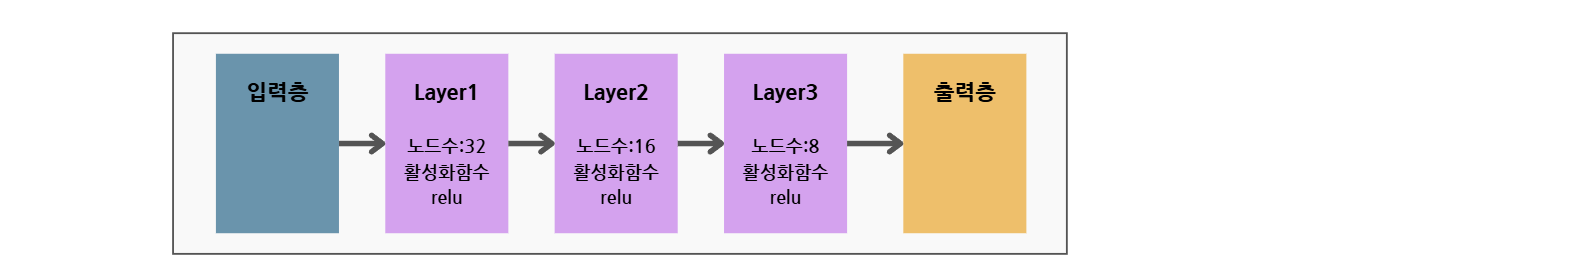

In [22]:
dl_model = Sequential([
    tf.keras.Input(shape=(X_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid'),
])
dl_model.summary()

Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 1,409 (5.50 KB)
 Trainable params: 1,409 (5.50 KB)
 Non-trainable params: 0 (0.00 B)


In [23]:
print(dl_model.count_params())

1409


#### **13. 과적합 방지를 위한 콜백(Callback)을 설정하고 모델 학습을 수행하여 최적의 성능을 확보하세요. 아래 가이드에 따라 학습의 효율을 높이는 콜백 함수를 정의하고, 딥러닝 모델의 컴파일 및 학습을 완료하세요.**
---
* **콜백(Callback) 설정**
    * 모델이 더 이상 개선되지 않을 때 학습을 자동 중단하여 과적합을 방지하는 **`EarlyStopping`** 을 설정하세요. 검증 손실(val_loss)을 모니터링하며, 개선이 없을 때 **5회**까지 기다리도록 설정합니다.
    * 학습 중 검증 정확도(val_accuracy)가 가장 높은 **최적의 모델 가중치만** 파일('best_model.keras')로 저장하도록 **`ModelCheckpoint`** 를 설정하세요.
* **모델 컴파일 및 학습**
    * 이진 분류 문제 해결에 가장 적합한 **손실 함수**를 지정하고, **'adam'** 최적화 도구를 적용하세요.
    * 스케일링이 완료된 학습용 독립 변수를 입력하고, 전체 데이터셋에 대해 **50회 반복 학습**이 이루어지도록 설정하세요.
    * 검증 데이터(X_test_scaled,y_test)를 검증 데이터로 활용하고, 정의한 두 가지 콜백 함수를 학습 과정에 연결하세요.
---

In [24]:
# (코드 셀) 지시사항에 따라 코드의 빈칸을 채우고 실행하세요.
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

checkpoint_dir.mkdir(parents=True, exist_ok=True)
es = EarlyStopping(monitor='val_loss', patience=5)
mc = ModelCheckpoint(checkpoint_dir / 'best_model.keras', monitor='val_accuracy', save_best_only=True, mode='max')

dl_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = dl_model.fit(
    X_train_scaled,
    y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test_scaled, y_test),
    callbacks=[es, mc]
)

학습 에포크 8/50
검증 손실 최솟값 0.321025


In [ ]:
# 답: 5

In [ ]:
# 답: True

In [ ]:
# 답: binary_crossentropy

In [ ]:
# 답: X_train_scaled

In [ ]:
# 답: epochs

#### **14. 저장된 최적의 딥러닝 모델을 로드하여 새로운 선수의 유망주 여부를 예측하세요. 아래 가이드에 따라 학습 과정에서 저장한 최적의 모델 가중치를 불러오고, 새로운 데이터를 모델의 입력 형식에 맞게 가공하여 유망주 여부를 최종 판별하세요.**
---
* **(14-1) 저장된 모델을 불러와 아래의 새로운 선수 데이터(`new_player`)에 대한 예측 결과를 출력하는 코드를 작성하세요.**
    * **모델 로드**: **`load_model`** 함수를 사용하여 문제 13에서 저장된 **`best_model.keras`** 파일을 불러오세요.
    * **예측 및 분류**: 모델을 통해 예측된 확률값이 **0.5 이상이면 1(유망주), 미만이면 0(일반 선수)** 으로 결과를 출력하세요.
* **(14-2) 새로운 선수 데이터(`new_player`)에 대한 모델의 최종 예측 결과(1 또는 0)는 무엇인가요?**
---

In [25]:
# 사전에 실행 후 정답 코드를 작성하시오.
# 새로운 선수 데이터(스케일링 완료 됨)
import numpy as np
from tensorflow.keras.models import load_model

new_player = np.array([[ 0.27578183, -0.38228264, -0.62939412,  1.86187261,  3.20874109,
         1.65577547, -0.1676898 ,  1.27431401, -0.67862179,  1.29496211,
         2.22893957,  8.85136187,  5.62266921,  1.81396294, -4.06365037,
         0.23520928,  0.2389859 ,  1.03756861, -0.5658021 , -0.32634444,
         1.34498653,  0.59891206]])

In [26]:
best_model = load_model(checkpoint_dir / 'best_model.keras')
prospect_probability = best_model.predict(new_player, verbose=0).item()
predicted_prospect = int(prospect_probability >= 0.5)
print(predicted_prospect)

1


In [27]:
print(predicted_prospect)

1
